# Лабораторная работа 4

Белдинова М.С., группа 6233, вариант 4 (набор данных MNIST)

Tensorflow 2.x

1) Подготовка данных

2) Использование Keras Model API

3) Использование Keras Sequential + Functional API

https://www.tensorflow.org/tutorials

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

%matplotlib inline

print('TensorFlow', tf.__version__)
device = '/device:GPU:0' if tf.config.list_physical_devices('GPU') else '/cpu:0'
print('Using device:', device)

TensorFlow 2.20.0
Using device: /cpu:0


# Подготовка данных
Набор данных из предыдущих лабораторных работ: MNIST (`load_digits`, изображения 8x8). Для Keras данные хранятся в формате (N, H, W, C) = (N, 8, 8, 1). Нормализация: вычитаем средний пиксель и делим на стандартное отклонение (по обучающей выборке).

In [2]:
def load_digits_data(num_validation=180, num_test=360, seed=0):
    digits = load_digits()
    X = np.asarray(digits.images, dtype=np.float32)[..., np.newaxis]   # (1797, 8, 8, 1)
    y = np.asarray(digits.target, dtype=np.int32)

    perm = np.random.RandomState(seed).permutation(X.shape[0])
    X, y = X[perm], y[perm]

    X_test, y_test = X[:num_test], y[:num_test]
    X_val, y_val = X[num_test:num_test + num_validation], y[num_test:num_test + num_validation]
    X_train, y_train = X[num_test + num_validation:], y[num_test + num_validation:]

    mean_pixel = X_train.mean(axis=(0, 1, 2), keepdims=True)
    std_pixel = X_train.std(axis=(0, 1, 2), keepdims=True)
    X_train = (X_train - mean_pixel) / std_pixel
    X_val = (X_val - mean_pixel) / std_pixel
    X_test = (X_test - mean_pixel) / std_pixel

    return X_train, y_train, X_val, y_val, X_test, y_test


X_train, y_train, X_val, y_val, X_test, y_test = load_digits_data()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape, y_train.dtype)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (1257, 8, 8, 1)
Train labels shape:  (1257,) int32
Validation data shape:  (180, 8, 8, 1)
Validation labels shape:  (180,)
Test data shape:  (360, 8, 8, 1)
Test labels shape:  (360,)


In [3]:
class Dataset(object):
    def __init__(self, X, y, batch_size, shuffle=False):
        """
        Итератор по мини-батчам.
        X - данные, y - метки (y.shape[0] == X.shape[0]),
        batch_size - размер батча, shuffle - перемешивать ли данные каждую эпоху
        """
        assert X.shape[0] == y.shape[0], 'Got different numbers of data and labels'
        self.X, self.y = X, y
        self.batch_size, self.shuffle = batch_size, shuffle

    def __iter__(self):
        N, B = self.X.shape[0], self.batch_size
        idxs = np.arange(N)
        if self.shuffle:
            np.random.shuffle(idxs)
        return iter((self.X[idxs[i:i+B]], self.y[idxs[i:i+B]]) for i in range(0, N, B))


train_dset = Dataset(X_train, y_train, batch_size=64, shuffle=True)
val_dset = Dataset(X_val, y_val, batch_size=64, shuffle=False)
test_dset = Dataset(X_test, y_test, batch_size=64)

В исходном классе Dataset при shuffle=True индексы перемешивались, но батчи брались по порядку из X (`self.X[i:i+B]`), то есть перемешивания фактически не было. Здесь батчи берутся по перемешанным индексам.

In [4]:
for t, (x, y) in enumerate(train_dset):
    print(t, x.shape, y.shape)
    if t > 5: break

0 (64, 8, 8, 1) (64,)
1 (64, 8, 8, 1) (64,)
2 (64, 8, 8, 1) (64,)
3 (64, 8, 8, 1) (64,)
4 (64, 8, 8, 1) (64,)
5 (64, 8, 8, 1) (64,)
6 (64, 8, 8, 1) (64,)


#  Keras Model Subclassing API

Для реализации собственной модели с помощью Keras Model Subclassing API:

1) Определить новый класс - наследник tf.keras.Model.

2) В методе __init__() определить все необходимые слои из модуля tf.keras.layers.

3) Реализовать прямой проход в методе call() на основе слоев, объявленных в __init__().

Пример - двухслойная полносвязная сеть:

In [5]:
class TwoLayerFC(tf.keras.Model):
    def __init__(self, hidden_size, num_classes):
        super(TwoLayerFC, self).__init__()
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.fc1 = tf.keras.layers.Dense(hidden_size, activation='relu',
                                   kernel_initializer=initializer)
        self.fc2 = tf.keras.layers.Dense(num_classes, activation='softmax',
                                   kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()

    def call(self, x, training=False):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.fc2(x)
        return x


def test_TwoLayerFC():
    input_size, hidden_size, num_classes = 50, 42, 10
    x = tf.zeros((64, input_size))
    model = TwoLayerFC(hidden_size, num_classes)
    with tf.device(device):
        scores = model(x)
        print(scores.shape)

test_TwoLayerFC()

(64, 10)


Трехслойная CNN для нашей задачи классификации.

Архитектура сети:

1. Сверточный слой (5 x 5 kernels, zero-padding = 'same')
2. Функция активации ReLU
3. Сверточный слой (3 x 3 kernels, zero-padding = 'same')
4. Функция активации ReLU
5. Полносвязный слой
6. Функция активации Softmax

In [6]:
class ThreeLayerConvNet(tf.keras.Model):
    def __init__(self, channel_1, channel_2, num_classes):
        super(ThreeLayerConvNet, self).__init__()
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.conv1 = tf.keras.layers.Conv2D(channel_1, (5, 5), padding='same', activation='relu',
                                            kernel_initializer=initializer)
        self.conv2 = tf.keras.layers.Conv2D(channel_2, (3, 3), padding='same', activation='relu',
                                            kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(num_classes, activation='softmax',
                                        kernel_initializer=initializer)

    def call(self, x, training=False):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.flatten(x)
        scores = self.fc(x)
        return scores

In [7]:
def test_ThreeLayerConvNet():
    channel_1, channel_2, num_classes = 12, 8, 10
    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)
    with tf.device(device):
        x = tf.zeros((64, 8, 8, 1))
        scores = model(x)
        print(scores.shape)

test_ThreeLayerConvNet()

(64, 10)


Цикл обучения. Отличия от шаблона: в Keras 3 у метрик метод `reset_states()` заменен на `reset_state()`; функция дополнительно возвращает модель и историю accuracy, чтобы потом строить графики.

In [8]:
print_every = 10

def train_part34(model_init_fn, optimizer_init_fn, num_epochs=1, is_training=False, verbose=True):
    """
    Обучение модели tf.keras на train_dset с периодической проверкой на val_dset.
    model_init_fn - функция без параметров, создающая модель
    optimizer_init_fn - функция без параметров, создающая оптимизатор
    num_epochs - число эпох
    is_training - флаг training для слоев (нужен для dropout и batchnorm)
    Возвращает модель и историю (train/val accuracy в конце каждой эпохи).
    """
    with tf.device(device):

        loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

        model = model_init_fn()
        optimizer = optimizer_init_fn()

        train_loss = tf.keras.metrics.Mean(name='train_loss')
        train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='train_accuracy')

        val_loss = tf.keras.metrics.Mean(name='val_loss')
        val_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='val_accuracy')

        history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

        def evaluate_val():
            val_loss.reset_state()
            val_accuracy.reset_state()
            for test_x, test_y in val_dset:
                prediction = model(test_x, training=False)
                t_loss = loss_fn(test_y, prediction)
                val_loss.update_state(t_loss)
                val_accuracy.update_state(test_y, prediction)

        t = 0
        for epoch in range(num_epochs):
            train_loss.reset_state()
            train_accuracy.reset_state()

            for x_np, y_np in train_dset:
                with tf.GradientTape() as tape:
                    scores = model(x_np, training=is_training)
                    loss = loss_fn(y_np, scores)
                    # регуляризационные потери слоев (если заданы kernel_regularizer)
                    if model.losses:
                        loss = loss + tf.add_n(model.losses)

                gradients = tape.gradient(loss, model.trainable_variables)
                optimizer.apply_gradients(zip(gradients, model.trainable_variables))

                train_loss.update_state(loss)
                train_accuracy.update_state(y_np, scores)

                if verbose and t % print_every == 0:
                    evaluate_val()
                    template = 'Iteration {}, Epoch {}, Loss: {:.4f}, Accuracy: {:.2f}, Val Loss: {:.4f}, Val Accuracy: {:.2f}'
                    print(template.format(t, epoch + 1,
                                          train_loss.result(),
                                          train_accuracy.result() * 100,
                                          val_loss.result(),
                                          val_accuracy.result() * 100))
                t += 1

            evaluate_val()
            history['train_acc'].append(float(train_accuracy.result()))
            history['val_acc'].append(float(val_accuracy.result()))
            history['train_loss'].append(float(train_loss.result()))
            history['val_loss'].append(float(val_loss.result()))
            if verbose:
                print('-- Epoch {} done: train acc {:.2f}, val acc {:.2f}'.format(
                    epoch + 1, history['train_acc'][-1] * 100, history['val_acc'][-1] * 100))

        return model, history


def test_accuracy(model):
    pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    return np.mean(pred == y_test)

Пример: обучение двухслойной полносвязной сети (1 эпоха).

In [9]:
tf.random.set_seed(0); np.random.seed(0)
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return TwoLayerFC(hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

_ = train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.5847, Accuracy: 20.31, Val Loss: 2.7076, Val Accuracy: 18.33


Iteration 10, Epoch 1, Loss: 1.7565, Accuracy: 52.41, Val Loss: 0.7271, Val Accuracy: 77.22


-- Epoch 1 done: train acc 69.45, val acc 82.22


Обучение трехслойной CNN, в tf.keras.optimizers.SGD используется момент Нестерова 0.9.

Требование: accuracy на валидационной выборке после 1 эпохи > 50%. В нашей обучающей выборке 1257 изображений, при batch_size = 64 это всего 20 итераций за эпоху, поэтому дополнительно к lr = 3e-3 из шаблона проверен шаг 1e-2.

In [10]:
channel_1, channel_2, num_classes = 32, 16, 10

def make_cnn_runs(lr):
    def model_init_fn():
        return ThreeLayerConvNet(channel_1, channel_2, num_classes)

    def optimizer_init_fn():
        return tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    return model_init_fn, optimizer_init_fn

for lr in [3e-3, 1e-2]:
    tf.random.set_seed(0); np.random.seed(0)
    print('learning_rate =', lr)
    model_init_fn, optimizer_init_fn = make_cnn_runs(lr)
    model, hist = train_part34(model_init_fn, optimizer_init_fn)
    print()

learning_rate = 0.003


Iteration 0, Epoch 1, Loss: 2.6188, Accuracy: 10.94, Val Loss: 2.5407, Val Accuracy: 13.33


Iteration 10, Epoch 1, Loss: 1.9857, Accuracy: 36.51, Val Loss: 1.3290, Val Accuracy: 65.56


-- Epoch 1 done: train acc 55.69, val acc 85.00

learning_rate = 0.01


Iteration 0, Epoch 1, Loss: 2.9844, Accuracy: 4.69, Val Loss: 2.4956, Val Accuracy: 11.11


Iteration 10, Epoch 1, Loss: 1.4308, Accuracy: 56.11, Val Loss: 0.4355, Val Accuracy: 90.56


-- Epoch 1 done: train acc 72.08, val acc 91.67



# Использование Keras Sequential API для реализации последовательных моделей.

Пример для полносвязной сети:

In [11]:
tf.random.set_seed(0); np.random.seed(0)
learning_rate = 1e-2

def model_init_fn():
    input_shape = (8, 8, 1)
    hidden_layer_size, num_classes = 4000, 10
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    layers = [
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_layer_size, activation='relu',
                              kernel_initializer=initializer),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

_ = train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 4.2787, Accuracy: 10.94, Val Loss: 3.9148, Val Accuracy: 16.11


Iteration 10, Epoch 1, Loss: 2.0536, Accuracy: 47.59, Val Loss: 0.6853, Val Accuracy: 79.44


-- Epoch 1 done: train acc 64.68, val acc 81.67


Альтернативный, менее гибкий способ обучения - compile + fit:

In [12]:
tf.random.set_seed(0); np.random.seed(0)
model = model_init_fn()
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val))
model.evaluate(X_test, y_test)

 1/20 ━━━━━━━━━━━━━━━━━━━━ 13s 705ms/step - loss: 2.9380 - sparse_categorical_accuracy: 0.0625

 9/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.4104 - sparse_categorical_accuracy: 0.2801   

19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.9061 - sparse_categorical_accuracy: 0.4405

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 1.1651 - sparse_categorical_accuracy: 0.6659 - val_loss: 0.4167 - val_sparse_categorical_accuracy: 0.8778


 1/12 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.1974 - sparse_categorical_accuracy: 0.9688

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4307 - sparse_categorical_accuracy: 0.8917 


[0.4306788146495819, 0.8916666507720947]

Трехслойная CNN, переписанная с помощью tf.keras.Sequential API. Обучение двумя способами: своим циклом train_part34 и через compile/fit.

In [13]:
tf.random.set_seed(0); np.random.seed(0)

def model_init_fn():
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    layers = [
        tf.keras.Input(shape=(8, 8, 1)),
        tf.keras.layers.Conv2D(channel_1, (5, 5), padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Conv2D(channel_2, (3, 3), padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

learning_rate = 5e-4
def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9, nesterov=True)

_ = train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.0161, Accuracy: 3.12, Val Loss: 2.6519, Val Accuracy: 10.00


Iteration 10, Epoch 1, Loss: 2.5202, Accuracy: 10.80, Val Loss: 2.1710, Val Accuracy: 23.89


-- Epoch 1 done: train acc 19.17, val acc 40.00


In [14]:
tf.random.set_seed(0); np.random.seed(0)
model = model_init_fn()
model.summary()
model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val))
model.evaluate(X_test, y_test)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 32)       │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,706 (61.35 KB)

 Trainable params: 15,706 (61.35 KB)

 Non-trainable params: 0 (0.00 B)

...

18/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.3270 - sparse_categorical_accuracy: 0.2804

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 1.6571 - sparse_categorical_accuracy: 0.5060 - val_loss: 0.9288 - val_sparse_categorical_accuracy: 0.7833


 1/12 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.6113 - sparse_categorical_accuracy: 0.9375

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9225 - sparse_categorical_accuracy: 0.7611 


[0.9224873781204224, 0.7611111402511597]

Из-за маленького размера выборки за одну эпоху делается всего 20 шагов, поэтому с шагом 5e-4 и с 'sgd' по умолчанию (lr = 0.01 без момента) за 1 эпоху сеть обучается хуже, чем с lr = 1e-2 и моментом Нестерова. Та же Sequential-модель за 10 эпох через fit:

In [15]:
tf.random.set_seed(0); np.random.seed(0)
model = model_init_fn()
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True),
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
h = model.fit(X_train, y_train, batch_size=64, epochs=10, validation_data=(X_val, y_val), verbose=2)
model.evaluate(X_test, y_test)

Epoch 1/10


20/20 - 2s - 83ms/step - loss: 0.7775 - sparse_categorical_accuracy: 0.7637 - val_loss: 0.1885 - val_sparse_categorical_accuracy: 0.9500


Epoch 2/10


20/20 - 0s - 15ms/step - loss: 0.1335 - sparse_categorical_accuracy: 0.9610 - val_loss: 0.1185 - val_sparse_categorical_accuracy: 0.9667


Epoch 3/10


...

Epoch 10/10


20/20 - 0s - 14ms/step - loss: 0.0122 - sparse_categorical_accuracy: 1.0000 - val_loss: 0.0879 - val_sparse_categorical_accuracy: 0.9778


 1/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0023 - sparse_categorical_accuracy: 1.0000

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1221 - sparse_categorical_accuracy: 0.9694 


[0.12210165709257126, 0.9694444537162781]

# Использование Keras Functional API

Для более сложных архитектур (несколько входов/выходов, повторное использование слоев, residual-связи) входные и выходные тензоры задаются явно.

Пример для полносвязной сети:

In [16]:
def two_layer_fc_functional(input_shape, hidden_size, num_classes):
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    inputs = tf.keras.Input(shape=input_shape)
    flattened_inputs = tf.keras.layers.Flatten()(inputs)
    fc1_output = tf.keras.layers.Dense(hidden_size, activation='relu',
                                 kernel_initializer=initializer)(flattened_inputs)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax',
                             kernel_initializer=initializer)(fc1_output)

    model = tf.keras.Model(inputs=inputs, outputs=scores)
    return model

def test_two_layer_fc_functional():
    input_size, hidden_size, num_classes = 50, 42, 10
    input_shape = (50,)

    x = tf.zeros((64, input_size))
    model = two_layer_fc_functional(input_shape, hidden_size, num_classes)

    with tf.device(device):
        scores = model(x)
        print(scores.shape)

test_two_layer_fc_functional()

(64, 10)


In [17]:
tf.random.set_seed(0); np.random.seed(0)
input_shape = (8, 8, 1)
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return two_layer_fc_functional(input_shape, hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

_ = train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.0676, Accuracy: 12.50, Val Loss: 2.5867, Val Accuracy: 22.78


Iteration 10, Epoch 1, Loss: 1.9410, Accuracy: 49.86, Val Loss: 0.7682, Val Accuracy: 77.22


-- Epoch 1 done: train acc 66.98, val acc 78.89


Та же трехслойная CNN через Functional API:

In [18]:
def three_layer_cnn_functional(input_shape, channel_1, channel_2, num_classes):
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(channel_1, (5, 5), padding='same', activation='relu',
                               kernel_initializer=initializer)(inputs)
    x = tf.keras.layers.Conv2D(channel_2, (3, 3), padding='same', activation='relu',
                               kernel_initializer=initializer)(x)
    x = tf.keras.layers.Flatten()(x)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax',
                                   kernel_initializer=initializer)(x)
    return tf.keras.Model(inputs=inputs, outputs=scores)

tf.random.set_seed(0); np.random.seed(0)
model, _ = train_part34(lambda: three_layer_cnn_functional((8, 8, 1), 32, 16, 10),
                        lambda: tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True),
                        num_epochs=3)
print('Test accuracy: %.4f' % test_accuracy(model))

Iteration 0, Epoch 1, Loss: 2.8671, Accuracy: 18.75, Val Loss: 2.3572, Val Accuracy: 17.22


Iteration 10, Epoch 1, Loss: 1.6675, Accuracy: 51.99, Val Loss: 0.6242, Val Accuracy: 86.11


-- Epoch 1 done: train acc 68.81, val acc 91.11
Iteration 20, Epoch 2, Loss: 0.3626, Accuracy: 84.38, Val Loss: 0.3068, Val Accuracy: 89.44


Iteration 30, Epoch 2, Loss: 0.2432, Accuracy: 91.62, Val Loss: 0.2325, Val Accuracy: 92.22


-- Epoch 2 done: train acc 93.32, val acc 93.33
Iteration 40, Epoch 3, Loss: 0.0794, Accuracy: 98.44, Val Loss: 0.2062, Val Accuracy: 95.00


Iteration 50, Epoch 3, Loss: 0.0999, Accuracy: 97.44, Val Loss: 0.1587, Val Accuracy: 96.11


-- Epoch 3 done: train acc 97.37, val acc 96.67


Test accuracy: 0.9722


# Эксперименты с архитектурой сверточной сети

Требование: не менее 70% accuracy на валидационной выборке за 10 эпох обучения.

Ниже проводится серия экспериментов (каждый - 10 эпох, одинаковые seed), меняются архитектура, нормализация, dropout, регуляризация, оптимизатор и функция потерь. Для каждого запуска запоминаются accuracy по эпохам, в конце все сводится в таблицу.

In [19]:
experiments = {}

def run_experiment(name, model_fn, opt_fn, num_epochs=10):
    tf.random.set_seed(0); np.random.seed(0)
    tic = time.time()
    model, hist = train_part34(model_fn, opt_fn, num_epochs=num_epochs, is_training=True, verbose=False)
    hist['time'] = time.time() - tic
    hist['params'] = model.count_params()
    hist['test_acc'] = test_accuracy(model)
    experiments[name] = hist
    print('%-38s params %7d | train acc %.4f | val acc %.4f (max %.4f) | test acc %.4f | %.1f c'
          % (name, hist['params'], hist['train_acc'][-1], hist['val_acc'][-1],
             max(hist['val_acc']), hist['test_acc'], hist['time']))

**Эксперимент 1. Базовая модель** - трехслойная CNN из задания (conv5x5(32) - conv3x3(16) - fc), SGD + Nesterov, и та же модель с Adam.

In [20]:
run_experiment('1a. 3-layer CNN, SGD nesterov',
               lambda: ThreeLayerConvNet(32, 16, 10),
               lambda: tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True))
run_experiment('1b. 3-layer CNN, Adam',
               lambda: ThreeLayerConvNet(32, 16, 10),
               lambda: tf.keras.optimizers.Adam(1e-3))

1a. 3-layer CNN, SGD nesterov          params   15706 | train acc 0.9992 | val acc 0.9611 (max 0.9722) | test acc 0.9722 | 11.9 c


1b. 3-layer CNN, Adam                  params   15706 | train acc 1.0000 | val acc 0.9722 (max 0.9778) | test acc 0.9667 | 16.3 c


**Эксперимент 2. Архитектура.** Модель CustomConvNet в стиле VGG: блоки [conv3x3 - conv3x3 - maxpool], затем полносвязный слой. Параметры конструктора позволяют включать батч-нормализацию, dropout и L2-регуляризацию, менять число фильтров и число блоков.

In [21]:
class CustomConvNet(tf.keras.Model):
    def __init__(self, filters=(32, 64), use_bn=True, dropout=0.3, l2=0.0,
                 hidden=128, num_classes=10, logits=False):
        super(CustomConvNet, self).__init__()
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
        self.use_bn = use_bn

        self.blocks = []
        for f in filters:
            block = []
            for _ in range(2):
                block.append(tf.keras.layers.Conv2D(f, (3, 3), padding='same', use_bias=not use_bn,
                                                    kernel_initializer=initializer, kernel_regularizer=reg))
                if use_bn:
                    block.append(tf.keras.layers.BatchNormalization())
                block.append(tf.keras.layers.ReLU())
            block.append(tf.keras.layers.MaxPool2D((2, 2)))
            if dropout > 0:
                block.append(tf.keras.layers.Dropout(dropout))
            self.blocks.append(block)

        self.flatten = tf.keras.layers.Flatten()
        self.fc1 = tf.keras.layers.Dense(hidden, kernel_initializer=initializer, kernel_regularizer=reg)
        self.bn_fc = tf.keras.layers.BatchNormalization() if use_bn else None
        self.relu_fc = tf.keras.layers.ReLU()
        self.drop_fc = tf.keras.layers.Dropout(dropout) if dropout > 0 else None
        # logits=True - на выходе оценки без softmax (для loss с from_logits)
        self.fc2 = tf.keras.layers.Dense(num_classes, activation=None if logits else 'softmax',
                                         kernel_initializer=initializer)

    def call(self, input_tensor, training=False):
        x = input_tensor
        for block in self.blocks:
            for layer in block:
                # training передается во все слои: важно для BatchNormalization и Dropout
                x = layer(x, training=training)
        x = self.flatten(x)
        x = self.fc1(x)
        if self.bn_fc is not None:
            x = self.bn_fc(x, training=training)
        x = self.relu_fc(x)
        if self.drop_fc is not None:
            x = self.drop_fc(x, training=training)
        x = self.fc2(x)
        return x

In [22]:
adam = lambda: tf.keras.optimizers.Adam(1e-3)

run_experiment('2a. VGG-like (32,64), no BN, no dropout',
               lambda: CustomConvNet(filters=(32, 64), use_bn=False, dropout=0.0), adam)
run_experiment('2b. VGG-like (16,32), no BN, no dropout',
               lambda: CustomConvNet(filters=(16, 32), use_bn=False, dropout=0.0), adam)
run_experiment('2c. VGG-like (32,), 1 блок, no BN',
               lambda: CustomConvNet(filters=(32,), use_bn=False, dropout=0.0), adam)

2a. VGG-like (32,64), no BN, no dropout params   99178 | train acc 1.0000 | val acc 0.9778 (max 0.9778) | test acc 0.9833 | 30.7 c


2b. VGG-like (16,32), no BN, no dropout params   34170 | train acc 1.0000 | val acc 0.9722 (max 0.9722) | test acc 0.9750 | 31.1 c


2c. VGG-like (32,), 1 блок, no BN      params   76522 | train acc 1.0000 | val acc 0.9833 (max 0.9833) | test acc 0.9806 | 21.1 c


**Эксперимент 3. Нормализация и регуляризация** (архитектура 2a).

In [23]:
run_experiment('3a. + BatchNorm',
               lambda: CustomConvNet(filters=(32, 64), use_bn=True, dropout=0.0), adam)
run_experiment('3b. + Dropout 0.3',
               lambda: CustomConvNet(filters=(32, 64), use_bn=False, dropout=0.3), adam)
run_experiment('3c. + BatchNorm + Dropout 0.3',
               lambda: CustomConvNet(filters=(32, 64), use_bn=True, dropout=0.3), adam)
run_experiment('3d. + BatchNorm + Dropout 0.3 + L2 1e-4',
               lambda: CustomConvNet(filters=(32, 64), use_bn=True, dropout=0.3, l2=1e-4), adam)
run_experiment('3e. + BatchNorm + Dropout 0.5',
               lambda: CustomConvNet(filters=(32, 64), use_bn=True, dropout=0.5), adam)

3a. + BatchNorm                        params  100266 | train acc 1.0000 | val acc 0.9778 (max 0.9778) | test acc 0.9917 | 51.7 c


3b. + Dropout 0.3                      params   99178 | train acc 0.9451 | val acc 0.9833 (max 0.9889) | test acc 0.9833 | 35.1 c


3c. + BatchNorm + Dropout 0.3          params  100266 | train acc 0.9602 | val acc 0.9889 (max 0.9889) | test acc 0.9833 | 56.5 c


3d. + BatchNorm + Dropout 0.3 + L2 1e-4 params  100266 | train acc 0.9650 | val acc 0.9778 (max 0.9778) | test acc 0.9667 | 83.7 c


3e. + BatchNorm + Dropout 0.5          params  100266 | train acc 0.7478 | val acc 0.8833 (max 0.8833) | test acc 0.8667 | 80.1 c


**Эксперимент 4. Методы оптимизации** (модель 3b: архитектура 2a + Dropout 0.3). По максимальной val accuracy она делит первое место с вариантом 3c (BN + Dropout), но проще и обучается быстрее, поэтому дальше используется она.

In [24]:
best_arch = lambda: CustomConvNet(filters=(32, 64), use_bn=False, dropout=0.3)

run_experiment('4a. SGD lr=1e-2',
               best_arch, lambda: tf.keras.optimizers.SGD(learning_rate=1e-2))
run_experiment('4b. SGD + Nesterov lr=1e-2',
               best_arch, lambda: tf.keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True))
run_experiment('4c. RMSprop lr=1e-3',
               best_arch, lambda: tf.keras.optimizers.RMSprop(1e-3))
run_experiment('4d. Adam lr=1e-2',
               best_arch, lambda: tf.keras.optimizers.Adam(1e-2))
run_experiment('4e. Adam lr=1e-4',
               best_arch, lambda: tf.keras.optimizers.Adam(1e-4))
run_experiment('4f. AdamW lr=1e-3, wd=1e-4',
               best_arch, lambda: tf.keras.optimizers.AdamW(1e-3, weight_decay=1e-4))

4a. SGD lr=1e-2                        params   99178 | train acc 0.7088 | val acc 0.9278 (max 0.9278) | test acc 0.9056 | 26.7 c


4b. SGD + Nesterov lr=1e-2             params   99178 | train acc 0.9499 | val acc 0.9889 (max 0.9889) | test acc 0.9806 | 34.6 c


4c. RMSprop lr=1e-3                    params   99178 | train acc 0.9451 | val acc 0.9889 (max 0.9889) | test acc 0.9806 | 38.8 c


4d. Adam lr=1e-2                       params   99178 | train acc 0.8966 | val acc 0.9667 (max 0.9778) | test acc 0.9639 | 50.2 c


4e. Adam lr=1e-4                       params   99178 | train acc 0.3317 | val acc 0.7333 (max 0.7333) | test acc 0.7306 | 53.5 c


4f. AdamW lr=1e-3, wd=1e-4             params   99178 | train acc 0.9467 | val acc 0.9778 (max 0.9778) | test acc 0.9833 | 53.1 c


**Эксперимент 5. Функция потерь.** Вместо softmax + SparseCategoricalCrossentropy используется кросс-энтропия со сглаживанием меток (label smoothing = 0.1): правильному классу ставится вероятность 0.9 вместо 1, это мешает сети становиться слишком уверенной. Для этого метки переводятся в one-hot, обучение идет через compile/fit.

In [25]:
def run_fit_experiment(name, model_fn, loss, num_epochs=10):
    tf.random.set_seed(0); np.random.seed(0)
    tic = time.time()
    model = model_fn()
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss,
                  metrics=[tf.keras.metrics.CategoricalAccuracy(name='acc')])
    h = model.fit(X_train, tf.one_hot(y_train, 10), batch_size=64, epochs=num_epochs,
                  validation_data=(X_val, tf.one_hot(y_val, 10)), verbose=0)
    hist = {'train_acc': h.history['acc'], 'val_acc': h.history['val_acc'],
            'train_loss': h.history['loss'], 'val_loss': h.history['val_loss'],
            'time': time.time() - tic, 'params': model.count_params(),
            'test_acc': test_accuracy(model)}
    experiments[name] = hist
    print('%-38s params %7d | train acc %.4f | val acc %.4f (max %.4f) | test acc %.4f | %.1f c'
          % (name, hist['params'], hist['train_acc'][-1], hist['val_acc'][-1],
             max(hist['val_acc']), hist['test_acc'], hist['time']))

run_fit_experiment('5a. CCE (fit)', best_arch,
                   tf.keras.losses.CategoricalCrossentropy())
run_fit_experiment('5b. CCE + label smoothing 0.1 (fit)', best_arch,
                   tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1))

5a. CCE (fit)                          params   99178 | train acc 0.9332 | val acc 0.9667 (max 0.9778) | test acc 0.9917 | 12.3 c


5b. CCE + label smoothing 0.1 (fit)    params   99178 | train acc 0.9578 | val acc 0.9778 (max 0.9833) | test acc 0.9917 | 10.9 c


Сводная таблица и графики.

In [26]:
summary = pd.DataFrame([
    {'эксперимент': name,
     'параметров': h['params'],
     'train acc (10 эп.)': round(h['train_acc'][-1], 4),
     'val acc (10 эп.)': round(h['val_acc'][-1], 4),
     'max val acc': round(max(h['val_acc']), 4),
     'эпох до val>=0.9': next((i + 1 for i, a in enumerate(h['val_acc']) if a >= 0.9), '-'),
     'test acc': round(h['test_acc'], 4),
     'время, c': round(h['time'], 1)}
    for name, h in experiments.items()])
pd.set_option('display.width', 200)
summary

,эксперимент,параметров,train acc (10 эп.),val acc (10 эп.),max val acc,эпох до val>=0.9,test acc,"время, c"
0,"1a. 3-layer CNN, SGD nesterov",15706,0.9992,0.9611,0.9722,1,0.9722,11.9
1,"1b. 3-layer CNN, Adam",15706,1.0000,0.9722,0.9778,2,0.9667,16.3
2,"2a. VGG-like (32,64), no BN, no dropout",99178,1.0000,0.9778,0.9778,2,0.9833,30.7
3,"2b. VGG-like (16,32), no BN, no dropout",34170,1.0000,0.9722,0.9722,4,0.9750,31.1
4,"2c. VGG-like (32,), 1 блок, no BN",76522,1.0000,0.9833,0.9833,2,0.9806,21.1
5,3a. + BatchNorm,100266,1.0000,0.9778,0.9778,3,0.9917,51.7
6,3b. + Dropout 0.3,99178,0.9451,0.9833,0.9889,4,0.9833,35.1
7,3c. + BatchNorm + Dropout 0.3,100266,0.9602,0.9889,0.9889,4,0.9833,56.5
8,3d. + BatchNorm + Dropout 0.3 + L2 1e-4,100266,0.9650,0.9778,0.9778,5,0.9667,83.7
9,3e. + BatchNorm + Dropout 0.5,100266,0.7478,0.8833,0.8833,-,0.8667,80.1


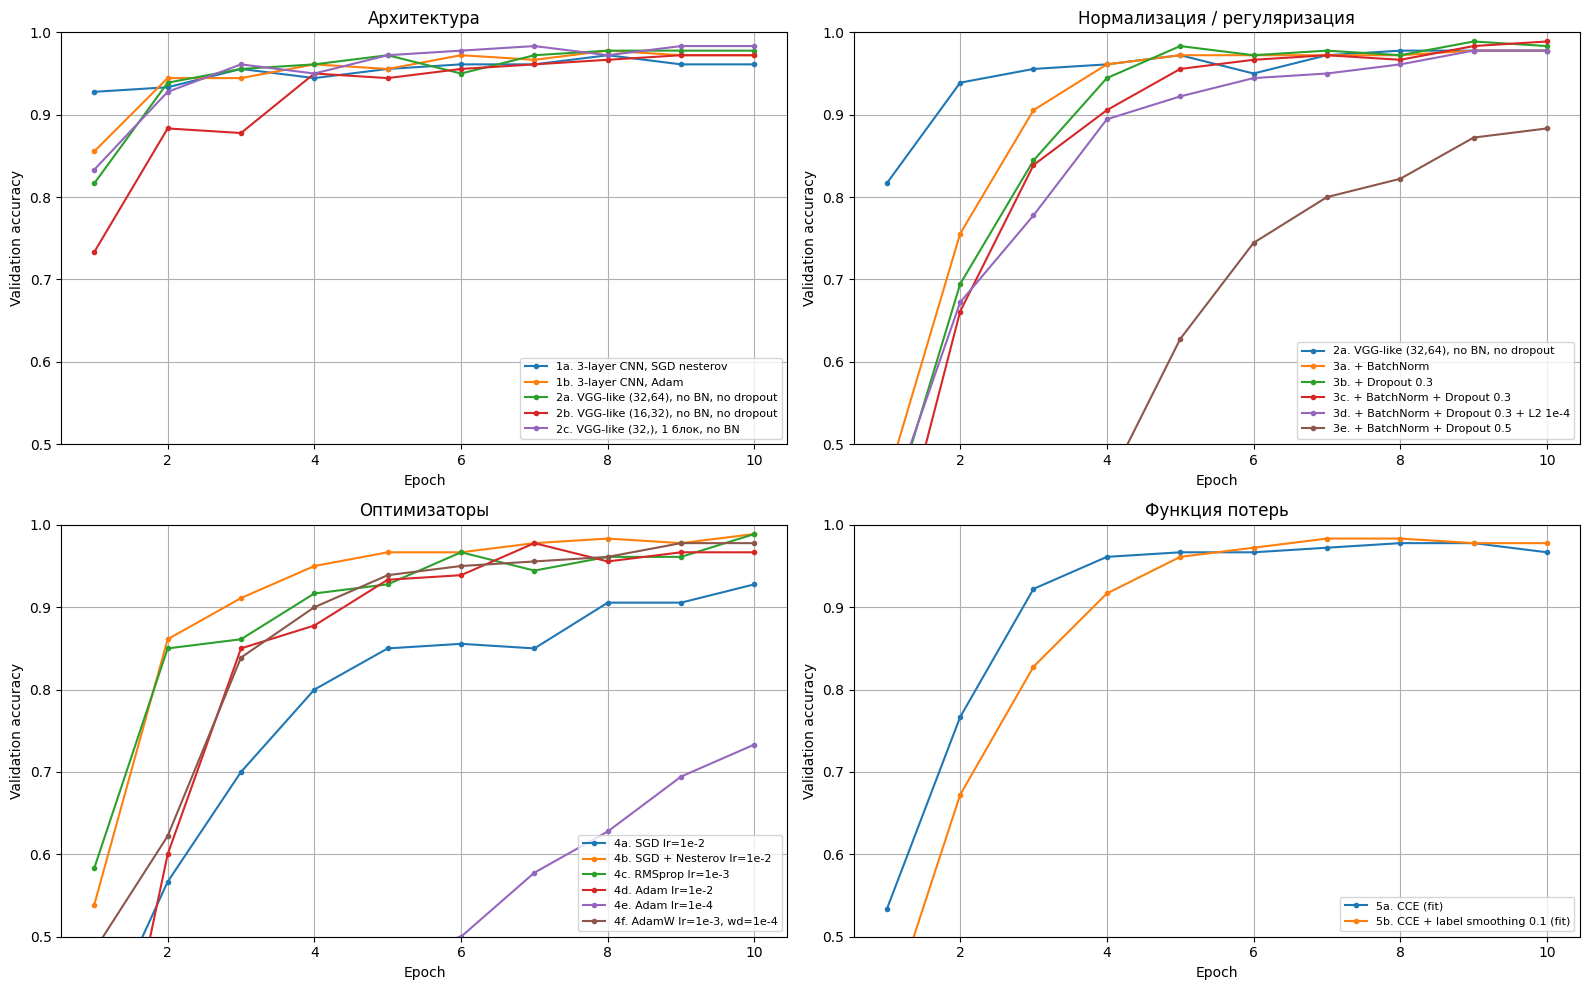

In [27]:
groups = {
    'Архитектура': ['1a', '1b', '2a', '2b', '2c'],
    'Нормализация / регуляризация': ['2a', '3a', '3b', '3c', '3d', '3e'],
    'Оптимизаторы': ['4a', '4b', '4c', '4d', '4e', '4f'],
    'Функция потерь': ['5a', '5b'],
}
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (title, keys) in zip(axes.ravel(), groups.items()):
    for name, h in experiments.items():
        if name.split('.')[0] in keys:
            ax.plot(range(1, len(h['val_acc']) + 1), h['val_acc'], '-o', markersize=3, label=name)
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Validation accuracy')
    ax.set_ylim(0.5, 1.0)
    ax.grid(True)
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

Итоговая модель CustomConvNet (2 блока conv-conv-pool с 32 и 64 фильтрами, Dropout 0.3, без BatchNorm, Adam lr = 1e-3), обучение 10 эпох с помощью train_part34 (как в шаблоне).

In [28]:
print_every = 40
num_epochs = 10

tf.random.set_seed(0); np.random.seed(0)

def model_init_fn():
    return CustomConvNet(filters=(32, 64), use_bn=False, dropout=0.3)

def optimizer_init_fn():
    learning_rate = 1e-3
    return tf.keras.optimizers.Adam(learning_rate)

model, history = train_part34(model_init_fn, optimizer_init_fn, num_epochs=num_epochs, is_training=True)

Iteration 0, Epoch 1, Loss: 4.8117, Accuracy: 7.81, Val Loss: 2.5213, Val Accuracy: 12.78


-- Epoch 1 done: train acc 16.71, val acc 62.78


-- Epoch 2 done: train acc 40.41, val acc 78.33


Iteration 40, Epoch 3, Loss: 1.4752, Accuracy: 45.31, Val Loss: 1.0640, Val Accuracy: 77.78


-- Epoch 3 done: train acc 59.51, val acc 87.22


...

-- Epoch 7 done: train acc 91.33, val acc 96.11


-- Epoch 8 done: train acc 92.52, val acc 97.78


Iteration 160, Epoch 9, Loss: 0.1790, Accuracy: 92.19, Val Loss: 0.0762, Val Accuracy: 98.33


-- Epoch 9 done: train acc 93.95, val acc 98.33


-- Epoch 10 done: train acc 96.02, val acc 98.89


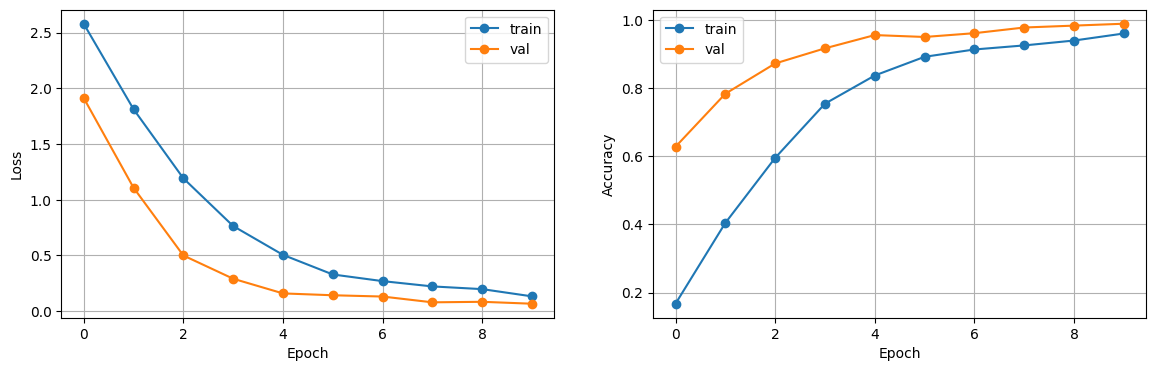

Validation accuracy: 0.9889


Test accuracy: 0.9861


In [29]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], '-o', label='train')
plt.plot(history['val_loss'], '-o', label='val')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], '-o', label='train')
plt.plot(history['val_acc'], '-o', label='val')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)
plt.show()

print('Validation accuracy: %.4f' % history['val_acc'][-1])
print('Test accuracy: %.4f' % test_accuracy(model))

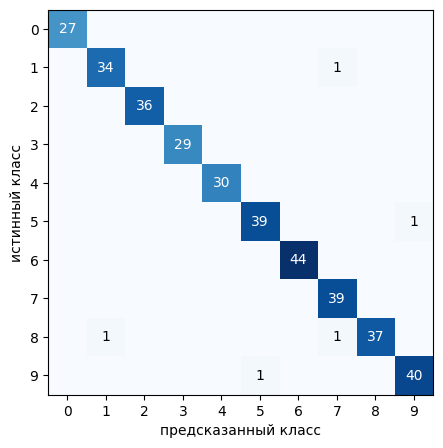

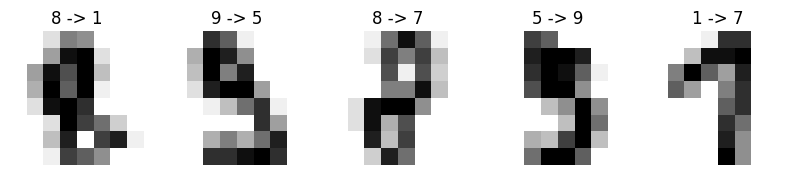

In [30]:
# матрица ошибок и неверно классифицированные изображения на тесте
pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
conf = tf.math.confusion_matrix(y_test, pred, num_classes=10).numpy()
plt.figure(figsize=(6, 5))
plt.imshow(conf, cmap='Blues')
for i in range(10):
    for j in range(10):
        if conf[i, j]:
            plt.text(j, i, conf[i, j], ha='center', va='center',
                     color='white' if conf[i, j] > conf.max() / 2 else 'black')
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel('предсказанный класс'); plt.ylabel('истинный класс')
plt.show()

wrong = np.flatnonzero(pred != y_test)
if len(wrong):
    plt.figure(figsize=(2 * len(wrong), 2.5))
    for i, idx in enumerate(wrong):
        plt.subplot(1, len(wrong), i + 1)
        plt.imshow(X_test[idx, :, :, 0], cmap='gray_r')
        plt.title('%d -> %d' % (y_test[idx], pred[idx]))
        plt.axis('off')
    plt.show()

## Описание экспериментов, результаты и выводы

**Подготовка и API.** Данные MNIST (8x8) приведены к формату (N, 8, 8, 1) и нормированы. В классе Dataset исправлено перемешивание батчей. Трехслойная CNN реализована тремя способами: через Model Subclassing API, Sequential API и Functional API; все варианты дают одинаковую архитектуру (15 706 параметров) и сопоставимый результат. Цикл обучения train_part34 адаптирован под Keras 3 (`reset_state`) и учитывает регуляризационные потери слоев.

**Трехслойная CNN, SGD + Nesterov.** После 1 эпохи val accuracy 85% при lr = 3e-3 и 91.7% при lr = 1e-2, требование > 50% выполнено. Обучение через compile/fit дает такие же результаты, как собственный цикл; за 10 эпох Sequential-модель достигает 97.8% на валидации.

**Эксперименты (по 10 эпох, требование - не менее 70% на валидации - выполнено во всех вариантах, кроме Adam с lr = 1e-4, который почти дошел до порога: 73%):**

1. *Архитектура.* Базовая 3-слойная CNN уже дает 96-97% на валидации. Более глубокие VGG-подобные модели (два блока conv-conv-pool) немного лучше: 97.2-98.3% на валидации, до 98.3% на тесте. Увеличение числа фильтров (16/32 -> 32/64) дает небольшой прирост. Для изображений 8x8 одного блока свертки достаточно (вариант 2c: 98.3%), третий блок был бы бессмысленным - после двух пулингов карта признаков уже 2x2.
2. *Нормализация и регуляризация.* Все модели без регуляризации доходят до 100% на обучающей выборке, то есть переобучаются. Dropout 0.3 снижает train accuracy до ~95% и повышает val accuracy до 98.9% (максимум). BatchNorm сам по себе не улучшил валидацию, но дал лучший результат на тесте (99.2%) и в сочетании с dropout тоже дает 98.9%. При этом модели с BN заметно медленнее по времени эпохи. Слишком сильный dropout (0.5) вместе с BN недообучает сеть за 10 эпох (88%). L2-регуляризация 1e-4 поверх BN и dropout ничего не добавила - регуляризации уже достаточно.
3. *Оптимизаторы.* SGD без момента сходится медленнее всех (92.8%, порог 90% только к 8-й эпохе). SGD + Nesterov и RMSprop дали лучший результат (98.9%), Adam/AdamW с lr = 1e-3 - 97.8-98.9%. Очень важен шаг обучения: Adam с lr = 1e-2 работает нестабильно (96.7%), а с lr = 1e-4 за 10 эпох (200 итераций) просто не успевает обучиться (73%).
4. *Функция потерь.* Сглаживание меток (label smoothing 0.1) немного повысило val accuracy (97.8% против 96.7% у обычной кросс-энтропии) при одинаковой точности на тесте (99.2%) - сеть становится менее "самоуверенной", что работает как дополнительная регуляризация.

**Итоговая модель** CustomConvNet: [conv3x3(32) - ReLU - conv3x3(32) - ReLU - maxpool - dropout] -> [conv3x3(64) - ReLU - conv3x3(64) - ReLU - maxpool - dropout] -> dense(128) - ReLU - dropout -> dense(10) - softmax, Adam lr = 1e-3, 10 эпох: **val accuracy 98.9%, test accuracy 98.6%**. Это лучше результатов предыдущих работ (kNN 98.3%, softmax 95.8%, двухслойная сеть 97.2% на тесте).

**Общие выводы.** На небольшом наборе MNIST 8x8 почти любая разумная сверточная сеть быстро достигает 96-99%, и разница между вариантами составляет 1-2%, что сравнимо с шумом (на валидации 180 изображений, одна ошибка = 0.56%; результаты между запусками на CPU немного отличаются). Наибольшее влияние на результат оказали выбор шага обучения и регуляризация (dropout), а не усложнение архитектуры. Keras позволяет описывать одну и ту же модель разными способами: Sequential удобен для простых последовательных сетей, Functional - для сетей со сложными связями, а Subclassing дает полный контроль над прямым проходом (например, передачей флага training в Dropout и BatchNormalization).